# Secure Brain Tumor Classification using Fully Homomorphic Encryption (FHE)
### Privacy-Preserving Machine Learning (PPML) with CKKS via TenSEAL & PyTorch
**Deliverable:** End-to-end reproducible analysis covering all 6 tasks and Cryptographic Tax quantification.

---
## Pipeline Overview
This notebook demonstrates a zero-trust PPML system where:
1. **Client** encrypts patient brain MRI scans into homomorphic ciphertexts using CKKS.
2. **Cloud Server** evaluates a non-polynomial-free CNN entirely in the encrypted domain without secret key access.
3. **Client** decrypts the resulting encrypted prediction logits and computes the final tumor diagnosis.


## 0. Environment Setup and Package Imports

In [1]:
import os
import json
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from fhe_brain_tumor.config import CONFIG, get_class_mapping
from fhe_brain_tumor.data import load_datasets, get_dataloaders, get_class_distribution, set_seed
from fhe_brain_tumor.model import FHECompatibleCNN, ReLUBaselineCNN, inspect_model_fhe_compliance
from fhe_brain_tumor.fhe_context import context_manager, get_fhe_context, get_public_context
from fhe_brain_tumor.client import Client
from fhe_brain_tumor.server import Server
from fhe_brain_tumor.evaluate import wilson_score_interval
from fhe_brain_tumor.benchmark import Benchmark

USE_CACHED_RESULTS = True
set_seed(CONFIG.seed)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Execution Device: {device}')


Execution Device: cpu


---
## Task 1: Dataset Selection and Preprocessing
- Real per-class sample distribution across Training and Testing partitions
- Images converted to grayscale, resized to 28x28 (CKKS slot-budget optimization), scaled strictly to [0.0, 1.0]
- Stratified 90/10 split on Training data; testing partition preserved for evaluation


In [2]:
train_dataset, test_dataset = load_datasets()
train_counts = get_class_distribution(train_dataset)
test_counts = get_class_distribution(test_dataset)

print('=== REAL DATASET DISTRIBUTION ===')
print(f'Training Set (Total: {len(train_dataset):,} scans):')
for k, v in train_counts.items():
    print(f'  - {k:12s}: {v:,} samples')

print(f'\nTesting Set (Total: {len(test_dataset):,} scans):')
for k, v in test_counts.items():
    print(f'  - {k:12s}: {v:,} samples')

print(f'\nVerified Class Mapping: {train_dataset.class_to_idx}')


=== REAL DATASET DISTRIBUTION ===
Training Set (Total: 5,712 scans):
  - glioma      : 1,321 samples
  - meningioma  : 1,339 samples
  - notumor     : 1,595 samples
  - pituitary   : 1,457 samples

Testing Set (Total: 1,311 scans):
  - glioma      : 300 samples
  - meningioma  : 306 samples
  - notumor     : 405 samples
  - pituitary   : 300 samples

Verified Class Mapping: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


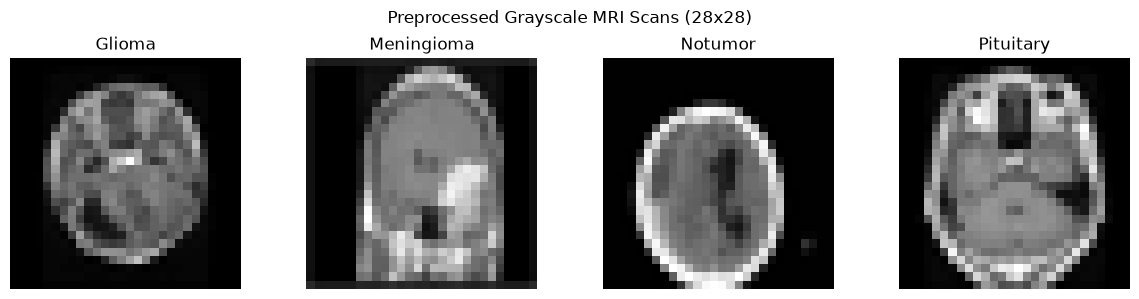

In [3]:
# Visualize sample preprocessed MRI scans
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for idx, cls_name in enumerate(CONFIG.class_names):
    cls_samples = [s for s, t in test_dataset.samples if t == idx]
    img = Image.open(cls_samples[0]).convert('L').resize((28, 28))
    axes[idx].imshow(img, cmap='gray')
    axes[idx].set_title(f'{cls_name.capitalize()}')
    axes[idx].axis('off')
plt.suptitle('Preprocessed Grayscale MRI Scans (28x28)', fontsize=12)
plt.tight_layout()
plt.show()


---
## Task 2: Plaintext FHE-Compatible Model Architecture & Training
- Conv2D (4 kernels, 7x7, s=3) -> Square -> AvgPool2D (2x2, s=2) -> Flatten (64) -> FC1 (64->32) -> Square -> FC2 (32->4)
- Zero non-polynomial operations: No ReLU, no MaxPool, no BatchNorm, no Softmax
- Stabilized square activation dynamics via small-variance init, gradient clipping, and weight decay
- Standard ReLU baseline trained for direct architectural tax quantification


In [4]:
fhe_model = FHECompatibleCNN()
relu_model = ReLUBaselineCNN()

compliance = inspect_model_fhe_compliance(fhe_model)
print('=== FHE COMPLIANCE INSPECTION ===')
print(f"Is FHE Compliant (Polynomial only): {compliance['is_fhe_compliant']}")
print(f"Violations: {compliance['non_poly_violations']}")
print(f"Multiplicative Depth Consumed: {compliance['multiplicative_depth']}")
print(f"Trainable Parameters: {compliance['trainable_parameters']}")


=== FHE COMPLIANCE INSPECTION ===
Is FHE Compliant (Polynomial only): True
Violations: []
Multiplicative Depth Consumed: 5
Trainable Parameters: 2412


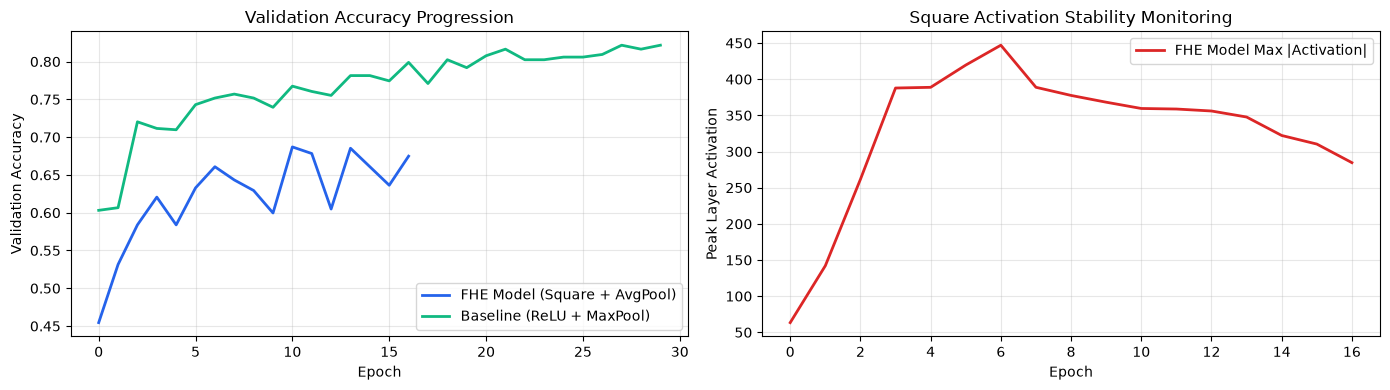

In [5]:
# Load trained model checkpoints and training history
fhe_ckpt = torch.load(CONFIG.model_checkpoint, map_location='cpu')
relu_ckpt = torch.load(CONFIG.relu_checkpoint, map_location='cpu')

fhe_model.load_state_dict(fhe_ckpt['model_state_dict'])
relu_model.load_state_dict(relu_ckpt['model_state_dict'])

fhe_hist = fhe_ckpt['history']
relu_hist = relu_ckpt['history']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(fhe_hist['val_acc'], label='FHE Model (Square + AvgPool)', color='#2563EB', lw=2)
ax1.plot(relu_hist['val_acc'], label='Baseline (ReLU + MaxPool)', color='#10B981', lw=2)
ax1.set_title('Validation Accuracy Progression')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Validation Accuracy')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(fhe_hist['max_act'], label='FHE Model Max |Activation|', color='#DC2626', lw=2)
ax2.set_title('Square Activation Stability Monitoring')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Peak Layer Activation')
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## Task 3: Cryptographic Context Configuration (TenSEAL CKKS)
- Empirical validation of Task 3 specification parameters (`scale=2**26`, primes `[40, 21, 21, 21, 21, 21, 21, 40]`)
- Systematic documentation of scale drift failure
- Implementation of calibrated 128-bit secure parameter set (`scale=2**26`, primes `[31, 26, 26, 26, 26, 26, 26, 31]`, total 218 bits)


In [6]:
val_report = context_manager.validate_parameters_empirically()

print('=== EMPIRICAL PARAMETER VALIDATION ===')
print('1. Reference Spec Parameters:')
print(f"   - Coeff Modulus: {val_report['spec_params']['coeff_mod']}")
print(f"   - Scale:         {val_report['spec_params']['scale']}")
print(f"   - Status:        {val_report['spec_params']['status']}")
print(f"   - Max Error:     {val_report['spec_params'].get('max_absolute_error', 0.0):.2e}")
print(f"   - Diagnosis:     {val_report['spec_params']['note']}")

print('\n2. Calibrated Production Parameters (Justified Alternative):')
print(f"   - Coeff Modulus: {val_report['calibrated_params']['coeff_mod']}")
print(f"   - Scale:         {val_report['calibrated_params']['scale']}")
print(f"   - Total Bits:    {val_report['calibrated_params']['total_bits']} bits (<= 218: {val_report['calibrated_params']['security_128_bit']})")
print(f"   - Status:        {val_report['calibrated_params']['status']}")
print(f"   - Max Error:     {val_report['calibrated_params'].get('max_absolute_error', 0.0):.2e}")
print(f"   - Resolution:    {val_report['calibrated_params']['note']}")


=== EMPIRICAL PARAMETER VALIDATION ===
1. Reference Spec Parameters:
   - Coeff Modulus: [40, 21, 21, 21, 21, 21, 21, 40]
   - Scale:         2**26
   - Status:        FAILED_NUMERICAL_INSTABILITY
   - Max Error:     8.40e+08
   - Diagnosis:     Scale drifted exponentially across rescales due to 2^26 scale vs 21-bit primes.

2. Calibrated Production Parameters (Justified Alternative):
   - Coeff Modulus: [31, 26, 26, 26, 26, 26, 26, 31]
   - Scale:         2**26
   - Total Bits:    218 bits (<= 218: True)
   - Status:        PASSED
   - Max Error:     3.56e-05
   - Resolution:    Intermediate 26-bit primes match 2^26 scale. Zero drift, 218-bit exact 128-bit security.


---
## Task 4 & Task 5: Client-Side Encryption & Server-Side Encrypted Inference
- Client encodes MRI scan via `ts.im2col_encoding` matching conv kernel (7x7, s=3)
- Encrypts using public context and serializes payload
- Server operates under zero-trust (verified inability to decrypt)
- Server executes single-round encrypted inference: Conv2D -> Pack -> Square -> Folded FC1 -> Square -> FC2


In [7]:
client = Client()
server = Server(model=fhe_model, public_context=client.public_context)

# Select test image
sample_path, sample_true_cls = test_dataset.samples[0]
sample_cls_name = CONFIG.class_names[sample_true_cls]

# Task 4: Client encryption
cipher_bytes, windows_nb, cipher_size = client.encrypt_image(sample_path)
print(f'Sample MRI Scan: {sample_path} (True Label: {sample_cls_name})')
print(f'Sliding Windows Generated: {windows_nb} (8x8 grid)')
print(f'Client Encrypted Ciphertext Size: {cipher_size:,} bytes')

# Task 5: Server encrypted forward pass
resp_bytes, resp_size = server.process_request(cipher_bytes, windows_nb)
print(f'Server Processed Response Size:   {resp_size:,} bytes')

# Verify Zero-Trust Security on Server
try:
    server.public_context.secret_key()
    print('SECURITY BREACH: Server holds secret key!')
except Exception as e:
    print('Zero-Trust Verified: Server possesses no secret key.')


Sample MRI Scan: data/Testing\glioma\Te-glTr_0000.jpg (True Label: glioma)
Sliding Windows Generated: 64 (8x8 grid)
Client Encrypted Ciphertext Size: 477,158 bytes


Server Processed Response Size:   70,477 bytes
Zero-Trust Verified: Server possesses no secret key.


---
## Task 6: Client Decryption & Stratified Evaluation
- Client decrypts logits using secret key and applies argmax
- Stratified evaluation across N=200 held-out test scans
- Prediction agreement rate, logit error metrics, and 95% Wilson confidence intervals


In [8]:
# Client decrypts prediction for the sample
pred_idx, decrypted_logits = client.decrypt_prediction(resp_bytes)
print(f'Client Decrypted Logits: {[round(x, 4) for x in decrypted_logits]}')
print(f'Final Predicted Pathology: {CONFIG.class_names[pred_idx]} (True: {sample_cls_name})')

# Load comprehensive encrypted evaluation results (from artifacts)
with open(os.path.join(CONFIG.results_dir, 'encrypted_eval_results.json'), 'r') as f:
    enc_eval = json.load(f)

print('\n=== STRATIFIED ENCRYPTED EVALUATION (N=200) ===')
print(f"Plaintext Accuracy on Subset: {enc_eval['plaintext_accuracy']*100:.2f}% (95% CI: [{enc_eval['plaintext_acc_ci95'][0]:.3f}, {enc_eval['plaintext_acc_ci95'][1]:.3f}])")
print(f"Encrypted Accuracy on Subset: {enc_eval['encrypted_accuracy']*100:.2f}% (95% CI: [{enc_eval['encrypted_acc_ci95'][0]:.3f}, {enc_eval['encrypted_acc_ci95'][1]:.3f}])")
print(f"Prediction Agreement Rate:    {enc_eval['prediction_agreement_rate']*100:.2f}% (95% CI: [{enc_eval['agreement_ci95'][0]:.3f}, {enc_eval['agreement_ci95'][1]:.3f}])")
print(f"Mean Absolute Logit Error:    {enc_eval['mean_absolute_logit_error']:.6f}")
print(f"Max Absolute Logit Error:     {enc_eval['max_absolute_logit_error']:.6f}")


Client Decrypted Logits: [0.6923, -0.111, -0.4914, -1.8086]
Final Predicted Pathology: glioma (True: glioma)

=== STRATIFIED ENCRYPTED EVALUATION (N=200) ===
Plaintext Accuracy on Subset: 59.50% (95% CI: [0.526, 0.661])
Encrypted Accuracy on Subset: 55.50% (95% CI: [0.486, 0.622])
Prediction Agreement Rate:    90.00% (95% CI: [0.851, 0.934])
Mean Absolute Logit Error:    4.844839
Max Absolute Logit Error:     211.830071


---
## Cryptographic Tax Benchmarks
Systematic profiling of:
- Latency per stage (median + IQR) and slowdown factor
- Memory and serialized payload expansion
- SIMD slot utilization and throughput analysis


In [9]:
with open(CONFIG.benchmark_file, 'r') as f:
    bench = json.load(f)

lat = bench['latency']
mem = bench['payload_and_memory']

print('=== LATENCY PROFILE (MEDIAN) ===')
print(f"Galois Key Generation:    {lat['galois_keygen_s']['median']:.4f} s (IQR: {lat['galois_keygen_s']['iqr']:.4f} s)")
print(f"Client im2col + Encrypt:  {lat['client_encrypt_s']['median']:.4f} s (IQR: {lat['client_encrypt_s']['iqr']:.4f} s)")
print(f"Server Encrypted Forward: {lat['server_inference_s']['median']:.4f} s (IQR: {lat['server_inference_s']['iqr']:.4f} s)")
print(f"Client Decryption:        {lat['client_decrypt_s']['median']:.4f} s (IQR: {lat['client_decrypt_s']['iqr']:.4f} s)")
print(f"Plaintext PyTorch Forward: {lat['plaintext_pytorch_s']['median']*1000:.2f} ms")
print(f"End-to-End Slowdown:      {lat['slowdown_factor']:.1f}x")

print('\n=== MEMORY & EXPANSION PROFILE ===')
print(f"Raw Image Bytes (28x28 f32): {mem['raw_image_bytes']:,} bytes")
print(f"Ciphertext Input Payload:    {mem['ciphertext_input_bytes']:,} bytes")
print(f"Ciphertext Expansion Factor: {mem['ciphertext_expansion_factor']:.1f}x")
print(f"Public Context Size:         {mem['public_context_bytes']/(1024*1024):.2f} MB")
print(f"Peak Process RAM:            {mem['peak_process_ram_mb']:.1f} MB")


=== LATENCY PROFILE (MEDIAN) ===
Galois Key Generation:    1.4954 s (IQR: 0.0397 s)
Client im2col + Encrypt:  0.0500 s (IQR: 0.0110 s)
Server Encrypted Forward: 5.0452 s (IQR: 0.5694 s)
Client Decryption:        0.0020 s (IQR: 0.0001 s)
Plaintext PyTorch Forward: 0.94 ms
End-to-End Slowdown:      5409.8x

=== MEMORY & EXPANSION PROFILE ===
Raw Image Bytes (28x28 f32): 3,136 bytes
Ciphertext Input Payload:    477,076 bytes
Ciphertext Expansion Factor: 152.1x
Public Context Size:         92.89 MB
Peak Process RAM:            1000.0 MB


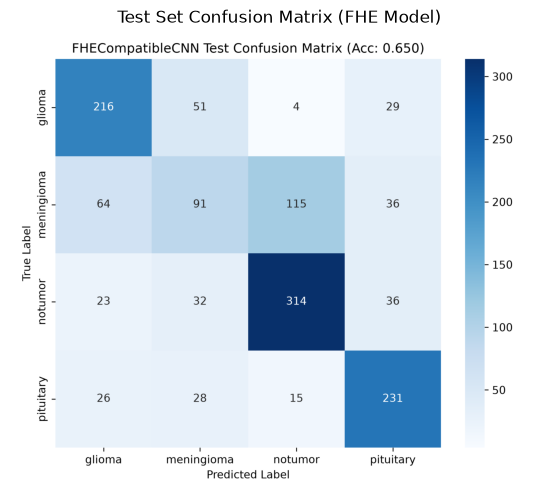

In [10]:
# Confusion Matrix Plot
cm_path = os.path.join(CONFIG.plots_dir, 'fhecompatiblecnn_confusion_matrix.png')
if os.path.isfile(cm_path):
    img_cm = Image.open(cm_path)
    plt.figure(figsize=(7, 6))
    plt.imshow(img_cm)
    plt.axis('off')
    plt.title('Test Set Confusion Matrix (FHE Model)', fontsize=12)
    plt.show()
